In [1]:
import shutil
import pandas as pd
import random

import copy
import numpy as np # Import numpy for checking finite values
import matplotlib.pyplot as plt # Import matplotlib for potential debugging

import os
import math # Import math for ceil
from sklearn.manifold import TSNE # Import TSNE to check default perplexity

import os
import glob
import json
import numpy as np
import tensorflow as tf
import sys

In [3]:
import sys
fixed_path = 'C:\\Users\\Enrico Didoli\\0.Master_Thesis\\'
if fixed_path not in sys.path:
    sys.path.append(fixed_path)

old_cellcnn_path = f'{fixed_path}CellCNN/Old_CellCNN/'
if old_cellcnn_path not in sys.path:
    sys.path.append(old_cellcnn_path)

cellcnn_path = f'{fixed_path}CellCNN/'
if cellcnn_path not in sys.path:
    sys.path.append(cellcnn_path)
    
general_functions_path = f'{fixed_path}General_Functions/'
if general_functions_path not in sys.path:
    sys.path.append(general_functions_path)

all_functions_path = f'{fixed_path}CellCNN/New running ipynb/Fixed/'
if all_functions_path  not in sys.path:
    sys.path.append(all_functions_path)

In [3]:
decache_files = ['timepoints_elaboration', 'results_elaboration', 'new_datasets_generation', 'run_models',
                 'old_cellCnn.model', 'old_cellCnn.utils', 'old_cellCnn.downsample', 'old_cellCnn.model_grid',
                'All_fixed_functions']

# Rimuovi il modulo specifico dalla cache
from timepoints_elaboration import remove_from_cache
remove_from_cache(decache_files)


# import downloaded modules
from old_cellCnn.model import CellCnn

import old_cellCnn.utils as utils
import old_cellCnn.downsample as downsample

from timepoints_elaboration import load_data, donation_extraction, dataset_elaboration
from timepoints_elaboration import donor_division, patient_code_extraction, remove_from_cache

from results_elaboration import extract_hyper, phenotype_prediction, default_serializer, show_hyperparameters
from results_elaboration import elaborate_predictions, show_hyper

from run_models import trials_train_CellCNN, trials_test_CellCNN, trials_train_CellCNN_old, trials_test_CellCNN_old

from new_datasets_generation import splitting_and_dataset_elaboration

from All_fixed_functions import remove_labels, show_blast_distribution, grid_or_rand_model, train_val_finalizing
from All_fixed_functions import prepare_results_to_save, retrieve_labels,subset_sampling, get_timepoints_predictions
from All_fixed_functions import get_trial_pred_per_timepoint, compute_timepoint_best_f1, find_threshold, print_var_memory, 
from All_fixed_functions import val_res_pred, find_robust_threshold, test_res_pred, final_trials_prediction, 

timepoints_elaboration rimosso dalla cache
results_elaboration non trovato nella cache
new_datasets_generation non trovato nella cache
run_models non trovato nella cache
old_cellCnn.model non trovato nella cache
old_cellCnn.utils non trovato nella cache
old_cellCnn.downsample non trovato nella cache
old_cellCnn.model_grid non trovato nella cache


In [4]:
'''
def remove_labels(new_test_datasets):
    new_no_label_test_datasets = []
    for dataset in new_test_datasets:
        
        if 'IsBlast' in dataset.columns:
            dataset = dataset.drop(columns = ['IsBlast'])
        
        new_no_label_test_datasets.append(dataset)
    print(len(new_no_label_test_datasets))
    return new_no_label_test_datasets

def show_blast_distribution(ALL_DATASETS, return_perc = False):
    tot_perc_list = []
    for i, dataset in enumerate(ALL_DATASETS):
        blast_n = (dataset['IsBlast'] == 1).sum()
        tot_perc_list.append(round((blast_n/len(dataset))*100, 2))
    
    positions = range(1, len(tot_perc_list) + 1)
    
    fig, ax1 = plt.subplots(figsize = [len(positions)/2,4])
    ax1.bar(list(range(1, len(tot_perc_list) + 1)), [max(tot_perc_list)]*len(tot_perc_list), alpha = 0.5)
    ax1.bar(list(range(1, len(tot_perc_list) + 1)), tot_perc_list)
    ax1.set_xticks(positions)
    
    ax2 = ax1.twiny()
    ax2.set_xlim(ax1.get_xlim())
    ax2.set_xticks(ax1.get_xticks()) # Positions [1, 2, 3, 4]
    
    ax2.set_xticklabels(tot_perc_list, size = 'x-small')
    plt.show()

    if return_perc:
        return tot_perc_list

def grid_or_rand_model(grid):
    if grid:
        remove_from_cache(['old_cellCnn.model_grid'])
        from old_cellCnn.model_grid import CellCnn
    else:
        remove_from_cache(['old_cellCnn.model'])
        from old_cellCnn.model import CellCnn
    return CellCnn

def train_val_finalizing(train_datasets, val_datasets, grid, labels):
    
    if grid:
        train = remove_labels(train_datasets)
        val = remove_labels(val_datasets)
        print(f'_abels from Train and Validations Sets have been REMOVED.\nGrid Search Ready!')
    else:
        if not labels: # if random search but we don't want use labels
            train = remove_labels(train_datasets)
            val = remove_labels(val_datasets)
            print(f'labels from Train and Validations Sets have been REMOVED.\nRandom Search Ready!')
            
        else:
            train = train_datasets
            val = val_datasets
            print(f'Labels from Train and Validations Sets have been PRESERVED.\nRandom Search Ready!')
            
    return train, val

def prepare_results_to_save(results_list, par_list = ['config', 'model_sorted_idx']):
    tot_trials_res = []

    for res in results_list:
        needed_results = {}
        for key, value in res.items():
            if key in par_list:
                needed_results[key] = value
                
        tot_trials_res.append(needed_results)
    return tot_trials_res

def retrieve_labels(datasets_extracted, remove = False, flat = False):
    """Extracts labels from a nested list of datasets
    Inputs: - datasets_extracted: colection of datatasets. Each element is a list itself. 
                                Outer list: patients. Inner list: time points provided by the patient 
            - remove: bool() -> If True, removes the labels from each cell
            - flat: bool() -> converts to a single list of dataframes (list of files)"""
    per_patient_datasets = []
    per_patient_y = []

    for patient in datasets_extracted:
        patient_datasets = []
        patient_ys = []
        for dataset in patient:
            if (dataset['IsBlast'] == 1).sum() > 0:
                patient_ys.append(1)
            else:
                patient_ys.append(0)
                
            if remove:
                dataset = dataset.drop(columns = ['IsBlast'])

            patient_datasets.append(dataset)


        per_patient_datasets.append(patient_datasets)
        per_patient_y.append(patient_ys)


    if flat:
        per_patient_datasets = flatten(per_patient_datasets)
        per_patient_y = flatten(per_patient_y)
        
    return per_patient_datasets, per_patient_y 

def subset_sampling(dataset, ncells, nsubsets, seed):
    resampled_datasets = []
    resampled_y = []
    blast_perc = []
    
    for i in range(nsubsets):
        seed += 10
        #print(f'seed:{seed}')
        resampled_cells = dataset.sample(ncells, replace = True, random_state = seed).reset_index(drop=True) # sample cells
            
        if (resampled_cells['IsBlast'] == 1).sum() > 0: #check label
                resampled_y.append(1)
                blast_perc.append((resampled_cells[resampled_cells['IsBlast'] == 1]).sum()/len(resampled_cells))
        else:
                resampled_y .append(0)
                blast_perc.append(0)
        resampled_cells = resampled_cells.drop(columns = ['IsBlast']) #remove isblast column

        resampled_datasets.append(resampled_cells) 
    return    resampled_datasets,  resampled_y , blast_perc, seed


def get_timepoints_predictions(total_pred_lists, per_donor_original_test_y, threshold):
    total_labels = []
    
    for patient in total_pred_lists:
        patient_timepoints_labels = []
        
        for timepoint in patient:
            timepoint_f1_scores = []
            blast_labelled_timepoint_scores = []
            
            true_y = timepoint.iloc[-1]
            
            for trial in range(len(timepoint.iloc[:-1])): # from each timepoint multiple samples has been generated. each sample has been predicted 10 times using the same 'best' model but using a different seed each time
                sub = timepoint.iloc[trial]               # each sub is a pediction of the 20 samples of a single timepoint
                blast_labelled_perc = sub.sum()/len(true_y)
                blast_labelled_timepoint_scores.append(blast_labelled_perc) #percentage of timepoints labelled as with blast cells
     
            mean_timepoint_blast_score = np.mean(blast_labelled_timepoint_scores) # mean percentage of timepoints labelled as with blast cells
            
            if mean_timepoint_blast_score >= threshold*0.01:
                patient_timepoints_labels.append(1)
            else:
                patient_timepoints_labels.append(0)
                
        total_labels.append(patient_timepoints_labels)
    return total_labels


def get_trial_pred_per_timepoint(total_pred_lists, per_donor_original_test_y):
    plot_data = []
    boxplot_data = []
    total_timepoint_prediction_per_trial = []
    
    for patient, patient_ys in zip(total_pred_lists, per_donor_original_test_y):
        timepoint_prediction_per_trial = []
        
        for timepoint, true_timepoint_y in zip(patient, patient_ys):
            label_str = "Positive" if true_timepoint_y == 1 else "Negative"
            
            trial_level_label_prediction = []
            true_y = timepoint.iloc[-1]
            timepoint_boxplot_data = []
            
            for trial in range(len(timepoint.iloc[:-1])): # from each timepoint multiple samples has been generated. each sample has been predicted 10 times using the same 'best' model but using a different seed each time
                sub = timepoint.iloc[trial]               # each sub is a pediction of the 20 samples of a single timepoint
                
                trial_perc = sub.sum()/len(true_y)
                #trial_perc = sub.sum()/min(1, true_y.sum())
            
                #trial_level_label_prediction.append((blast_labelled_perc >= threshold*0.01).astype(int))
                plot_data.append({
                "True_Label": label_str,
                "Timepoint_Score": trial_perc
                })
                
                timepoint_boxplot_data.append(trial_perc)
                
            boxplot_data.append({
                "True_Label": true_timepoint_y,
                "Timepoint_trials_scores": timepoint_boxplot_data
                })
                
    return plot_data, boxplot_data

def compute_timepoint_best_f1(timepoint_preds):
        """we are taking the best f1 score. because we are not tuning the model. we are just trying to predict the label of the timepoint"""
        timepoint_score = []
        
        resampled_true_y = timepoint_preds.iloc[-1] # get labels of resampled subsets
        #print(timepoint_preds.iloc[:-1]) #labels

        # initialize variables
        best_f1 = -1
        counter = 0
        
        for h in range(len(timepoint_preds) - 1):
            sub = timepoint_preds.iloc[h] # extrsct trial pediction
            
            f1 = f1_score(resampled_true_y, sub, pos_label = 1) # compute the f1_score
            if f1 > best_f1:
                best_f1_idx = counter
            counter += 1
            
        print(best_f1_idx)   
        best_sub = timepoint_preds.iloc[best_f1_idx]
        #print(len(true_y))
        blast_score = best_sub.sum() 
        print('')
        #print(best_sub)
        #print(f'blast_score: {blast_score}\n')
        timepoint_score = blast_score.sum()/len(resampled_true_y)
        return (timepoint_score, list(resampled_true_y))


def find_threshold(total_scores, per_donor_original_val_y):
    best_f1 = -1
    best_thr = -1
    tot_mean_f1_scores = []
    threshold_predictions = []
    for threshold in list(range(1,101)):
        f1_scores = []
        patient_predictions = []
        for patient_score, patient_y in zip(total_scores, per_donor_original_val_y):
            scores = []
            
            for timep in patient_score:
                # get mean columns predicted probabilities 
                scores.append(timep[0]) 
            
            y_pred = []
            y_pred = (np.array(scores) >= threshold*0.01).astype(int) #checks column by column if the element is > than the threshold and converts it in 1 or 0
            #print(f'Threshold: {threshold*0.01}. Preds: {y_pred}')
            #print(patient_y)
            #print(y_pred)
            timepoint_f1_score = f1_score(patient_y, y_pred, pos_label = 1, zero_division=1)
            #print(f'f1_score: {timepoint_f1_score}\n')
        
            f1_scores.append(timepoint_f1_score)
            
            patient_predictions.append(list(y_pred))
            
        threshold_predictions.append(patient_predictions)
    
        #print(f1_scores)
        mean_f1_score = np.mean(f1_scores)
        tot_mean_f1_scores.append(mean_f1_score)
        
        if mean_f1_score > best_f1:
                best_f1 = mean_f1_score
                best_thr = threshold*0.01
        #print('')
    
        #patient_f1_scores.append(timepoint_f1_score)
    #plot thresholds
    plt.plot(list(range(1,101)), tot_mean_f1_scores)
    #for th in threshold_predictions:
        #print(th)

    #find threshold
    max_mean_f1 = max(tot_mean_f1_scores)
    best_thresholds_idx = []
    
    best_thresholds_idx = [i for i, f1 in enumerate(tot_mean_f1_scores) if f1 == max_mean_f1]
    #print(best_thresholds_idx)
    
    robust_best_thr_idx = np.median(best_thresholds_idx)
    #print(np.median(list(range(5))))
    print(f'Chosen threshold: {robust_best_thr_idx}' )
    return robust_best_thr_idx


def flatten(nested):
    if nested is None:
        return []
    if not isinstance(nested, (list, tuple)):
        return [nested]
    nested = list(nested)
    result = []
    for item in nested:
        result.extend(flatten(item))
    return result
'''

In [9]:
import json
config_path = f'{fixed_path}CellCNN\\results\\old\\n_sub_tuning\\'
with open(f'{config_path}configuration_positive_highest_first.json', 'r', encoding="utf-8") as f:
    config = json.load(f)
print(config)

seed = config['seed']
n_sub = config['n_sub']
n_cells = config['n_cells']
blast_perc = config['blast_perc']
best_nsub = config['best_nsub']

print(seed)
print(n_sub)
print(n_cells)
print(blast_perc)
print(best_nsub)

ncell_path = f'{fixed_path}CellCNN\\results\\old\\ncells_tuning\\'
with open(f'{ncell_path}best_ncells.json', 'r', encoding="utf-8") as f:
    best_ncells = json.load(f)[0]
print(best_ncells)

{'seed': 105619, 'n_sub': 5, 'n_cells': 100000, 'blast_perc': [0.0001, 0.0005, 0.001, 0.005, 0.01], 'best_nsub': 940, 'sorted_nsubs_list': [820, 900, 920, 940, 1000], 'acc_5_to_plot': [[0.6, 0.6, 0.64, 0.68, 0.6], [0.6, 0.96, 0.64, 0.6, 0.6], [0.6, 1.0, 0.68, 0.64, 0.88], [0.68, 0.6, 0.72, 0.6, 0.6], [0.6, 0.68, 0.6, 0.68, 0.6]], 'f1_5_to_plot': [[0.0, 0.0, 0.18181818181818182, 0.3333333333333333, 0.0], [0.0, 0.9473684210526315, 0.18181818181818182, 0.0, 0.0], [0.0, 1.0, 0.3333333333333333, 0.18181818181818182, 0.8235294117647058], [0.3333333333333333, 0.0, 0.46153846153846156, 0.0, 0.0], [0.0, 0.3333333333333333, 0.0, 0.3333333333333333, 0.0]], 'seed_list': [7359, 9654, 4557, 106, 2615, 6924, 5574, 4552, 2547, 3527, 18953, 23855, 81725, 6398, 3184, 6416, 78297, 96915, 17792, 96841]}
105619
5
100000
[0.0001, 0.0005, 0.001, 0.005, 0.01]
940
200


In [6]:
%%time

# Trova tutti i file con estensione specifica in una cartella
data_folder = f'{fixed_path}B-ALL_Datasets'
extension = '*.csv'  # cambia con l'estensione che ti serve

multiple_donations, ALL_DATASETS = load_data(data_path = data_folder, ext = extension)

Elaborating file 0: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_220204-2900.csv
Elaborating file 1: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_220208-3665.csv
Elaborating file 2: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_220216-3546.csv
Elaborating file 3: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_B-ALL_GHE11_D15_1.csv
Elaborating file 4: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_B-ALL_GHE11_D29_1.csv
Elaborating file 5: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_B-ALL_GHE11_D71_1.csv
Elaborating file 6: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_B-ALL_GHE12_D15_2.csv
Elaborating file 7: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_B-ALL_GHE12_D29_1.csv
Elaborating file 8: C:\Users\Enrico Didoli\0.Master_Thesis

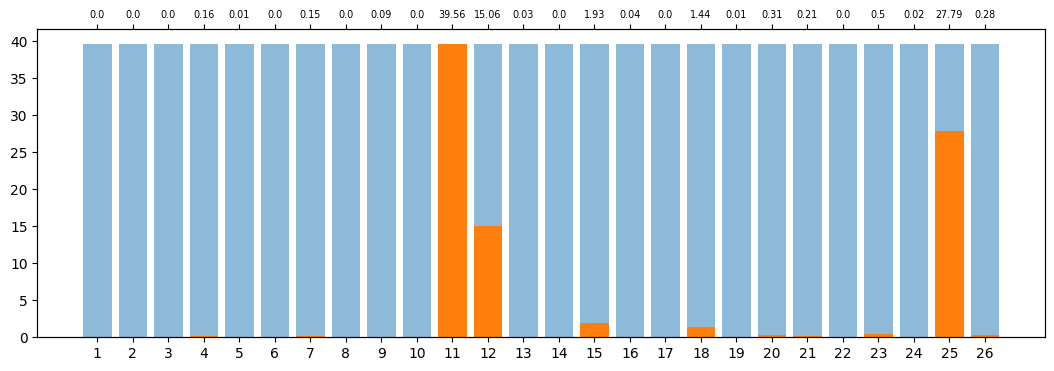

In [7]:

show_blast_distribution(ALL_DATASETS, return_perc = False)

In [8]:
healthy_donors, blast_donors, mixed_donors = donor_division(multiple_donations, ALL_DATASETS)

print(healthy_donors, blast_donors, mixed_donors)

{'11': [1, 1, 0], '12': [1, 1], '1': [1, 0], '2': [1, 1], '3': [1, 0], '4': [1, 1, 0], '6': [1, 1], '7': [1, 1, 0], '8': [1, 1], '9': [1, 1], '13': [0], '14': [0], '15': [0]}
['13', '14', '15'] ['12', '2', '6', '8', '9'] ['11', '1', '3', '4', '7']


In [9]:
# Samples donors for Train, Validation and Test sets    
seed = 105619

train_donors_idx, val_donors_idx, test_donors_idx = dataset_elaboration(multiple_donations, ALL_DATASETS, healthy_donors, blast_donors,
                        mixed_donors, seed = seed)

#train_donors_idx, val_donors_idx, test_donors_idx = ['3', '15', '6', '7', '9'] ['13', '12'] ['2', '8', '14', '11', '1', '4']

Precess starts. Dividing donors...
healthy_donors_idx, blast_donors_idx, mixed_donors_idx: [0, 2, 1], [0, 4, 2, 1, 3],[4, 0, 2, 1, 3]
Seting Train, Validation and Test idx...
['12', '9', '13', '7'] ['6', '15', '3'] ['2', '8', '14', '11', '1', '4']


In [10]:

#  Retrieves specific donor datasets from all datasets list
train_datasets_extracted = donation_extraction(train_donors_idx, multiple_donations, ALL_DATASETS)
val_datasets_extracted = donation_extraction(val_donors_idx, multiple_donations, ALL_DATASETS)
test_datasets_extracted = donation_extraction(test_donors_idx, multiple_donations, ALL_DATASETS)


print(len(train_datasets_extracted)) # list of donators
print(len(train_datasets_extracted[0])) # list of donations
print(len(test_datasets_extracted[0][0])) # dataset of cells

4
2
778750


In [13]:
max_len = 0
for i, pat in enumerate(val_datasets_extracted):
    for j, ds in enumerate(pat):
        if len(ds) > max_len:
            max_len = len(ds)
        print(f'Patient {val_donors_idx[i]}: cells: {len(ds)}')

min_perc = 1/max_len

min_sub_to_sample_val = np.log(min_perc/max_len)/np.log(0.51923)


max_len = 0
for i, pat in enumerate(test_datasets_extracted):
    for j, ds in enumerate(pat):
        if len(ds) > max_len:
            max_len = len(ds)
        print(f'Patient {test_donors_idx[i]}: cells: {len(ds)}')

min_perc = 1/max_len

min_sub_to_sample_test = np.log(min_perc/max_len)/np.log(0.51923)

print(f'Subset to sample in Threshold Tuning: {min_sub_to_sample_val}')
print(f'Subset to sample in Label Prediction: {min_sub_to_sample_test}')

Patient 6: cells: 637409
Patient 6: cells: 2928000
Patient 15: cells: 1291729
Patient 3: cells: 208000
Patient 3: cells: 2912500
Patient 2: cells: 778750
Patient 2: cells: 5510750
Patient 8: cells: 479000
Patient 8: cells: 455000
Patient 14: cells: 2764877
Patient 11: cells: 843500
Patient 11: cells: 1404000
Patient 11: cells: 3265250
Patient 1: cells: 864000
Patient 1: cells: 1947518
Patient 4: cells: 160500
Patient 4: cells: 3591480
Patient 4: cells: 3107000
Subset to sample in Threshold Tuning: 45.43680444779809
Subset to sample in Label Prediction: 47.366536192398286


In [1]:
import sys
import numpy as np
import pandas as pd
'''

def print_var_memory(var_to_check = None):
    def get_actual_size(obj):
        """Get TRUE memory size"""
        if isinstance(obj, pd.DataFrame):
            return obj.memory_usage(deep=True).sum()
        elif isinstance(obj, pd.Series):
            return obj.memory_usage(deep=True)
        elif isinstance(obj, np.ndarray):
            return obj.nbytes
        elif isinstance(obj, (list, tuple, set, dict)):
            # For containers, sum up contents
            return sys.getsizeof(obj) + sum(sys.getsizeof(item) for item in obj)
        else:
            return sys.getsizeof(obj)
            
    # Display all variables with ACTUAL sizes
    all_vars = %who_ls
    sizes = []
    if var_to_check is None:
        var_to_check = all_vars

    
    for var_name in all_vars:
        #try:
            var = eval(var_name)
           
            #if var_name in  ('train_datasets_extracted','val_datasets_extracted','test_datasets_extracted'):
            if var_name in var_to_check:
                #print(var)
                if isinstance(var, (list, tuple)):
                    var = flatten(var)
                    tot = 0
                    for element in var:
                        tot += get_actual_size(element)
                    size = tot
                    sizes.append((var_name, type(var).__name__, size))
            else:
                size = get_actual_size(var)
                sizes.append((var_name, type(var).__name__, size))
        
        #except:
        #    pass
    
    # Sort by size
    sizes.sort(key=lambda x: x[2], reverse=True)
    
    # Pretty print
    print(f"{'Variable':<25} {'Type':<20} {'Memory':>15}")
    print("-" * 65)
    total = 0
    var_to_check = []
    for name, type_name, size in sizes:
        total += size
        if size > 1024**3:  # GB
            print(f"{name:<25} {type_name:<20} {size/(1024**3):>12.2f} GB")
            var_to_check.append(name)
            
        elif size > 1024**2:  # MB
            print(f"{name:<25} {type_name:<20} {size/(1024**2):>12.2f} MB")
            var_to_check.append(name)
        '''
        '''
        elif size > 1024:  # KB
            print(f"{name:<25} {type_name:<20} {size/1024:>12.2f} KB")
        
        else:
            print(f"{name:<25} {type_name:<20} {size:>12} bytes")
        '''
        '''
    print("-" * 65)
    print(f"{'TOTAL':<25} {'':<20} {total/(1024**3):>12.2f} GB")
    return var_to_check
'''   
print_var_memory()

Variable                  Type                          Memory
-----------------------------------------------------------------
-----------------------------------------------------------------
TOTAL                                                  0.00 GB


[]

In [15]:
del ALL_DATASETS
del train_datasets_extracted
del val_datasets_extracted
del new_test_datasets
print_var_memory()


Variable                            Type             Data/Info
--------------------------------------------------------------
ALL_DATASETS                        list             n=26
CellCnn                             type             <class 'old_cellCnn.model.CellCnn'>
TSNE                                type             <class 'sklearn.manifold._t_sne.TSNE'>
b_pat                               list             n=3
best_nsub                           int              980
blast_donors                        list             n=5
blast_perc                          list             n=3
cellcnn_path                        str              C:\Users\Enrico Didoli\0.Master_Thesis\CellCNN/
compute_timepoint_best_f1           function         <function compute_timepoi<...>f1 at 0x00000210D8DD68B0>
config                              dict             n=9
config_path                         str              C:\Users\Enrico Didoli\0.<...>results\old\n_sub_tuning\
copy                           

# Rerun from here

New training datasets creation...
4
2

New Donor
2
Tot blast data in the donor timepoints: 639
Tot blast data in the donor timepoints: 654
Extraction Done
Condition: 1
3
1
1
[0.001, 0.005, 0.01]
3
Chosen # of blast cells: [ 100.  500. 1000.  100.]
Chosen # of blast cells: [ 100.  100.  500. 1000.]

New Donor
2
Tot blast data in the donor timepoints: 44697
Tot blast data in the donor timepoints: 46110
Extraction Done
Condition: 1
3
1
1
[0.001, 0.005, 0.01]
3
Chosen # of blast cells: [ 100.  500. 1000.  100.]
Chosen # of blast cells: [ 100.  100.  500. 1000.]

New Donor
1
Timepoint condition: Healthy
Extraction Done
Condition: 0

New Donor
3
Tot blast data in the donor timepoints: 518
Tot blast data in the donor timepoints: 916
Tot blast data in the donor timepoints: 916
Extraction Done
Condition: 1
3
1
1
[0.001, 0.005, 0.01]
3
Chosen # of blast cells: [ 100.  500. 1000.  100.]
Chosen # of blast cells: [ 100.  100.  500. 1000.]
[1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0,

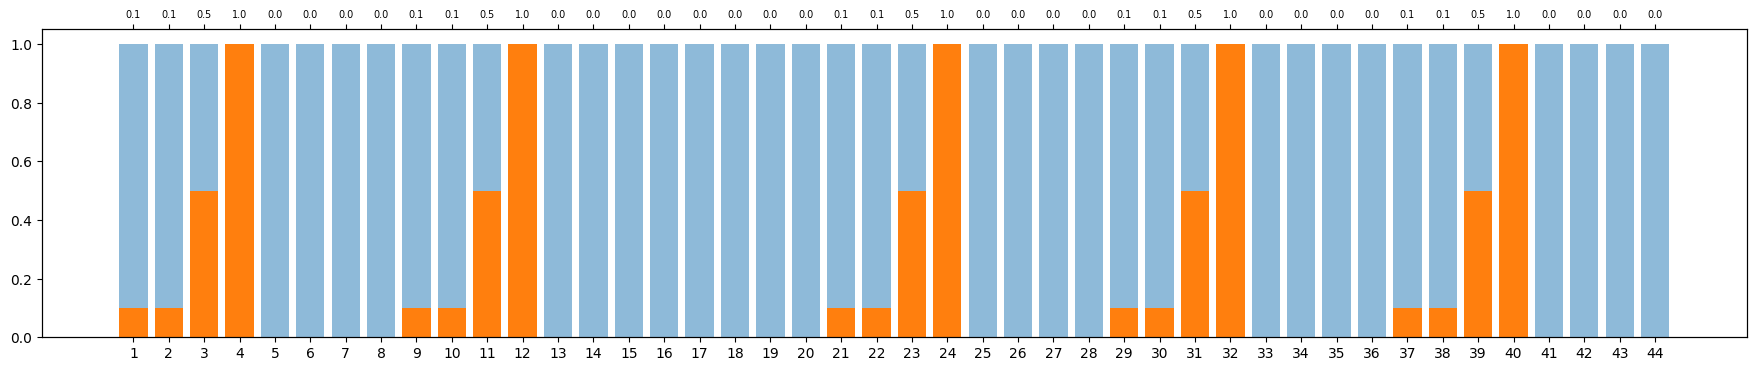

20
20


In [16]:
n_sub = 3
#seed = 42
#n_cells = 100000
blast_perc = [0.001, 0.005, 0.01]

new_train_datasets, new_train_y, new_val_datasets, new_val_y, new_test_datasets, new_test_y = splitting_and_dataset_elaboration(train_datasets_extracted, 
                                                                                    val_datasets_extracted, test_datasets_extracted,
                                                                                    n_sub, n_cells, seed, blast_perc = blast_perc, per_perc = True)

show_blast_distribution(new_test_datasets)
print(len(new_val_datasets))
print(len(new_val_y))

In [17]:
del ALL_DATASETS
print_var_memory()

Variable                  Type                          Memory
-----------------------------------------------------------------
test_datasets_extracted   list                         1.13 GB
train_datasets_extracted  list                       407.55 MB
val_datasets_extracted    list                       365.19 MB
pat                       list                       313.98 MB
new_test_datasets         list                       201.42 MB
new_train_datasets        list                       128.18 MB
new_val_datasets          list                        91.56 MB
-----------------------------------------------------------------
TOTAL                                                  2.60 GB


['test_datasets_extracted',
 'train_datasets_extracted',
 'val_datasets_extracted',
 'pat',
 'new_test_datasets',
 'new_train_datasets',
 'new_val_datasets']

In [18]:

original_test_datasets, original_test_y = retrieve_labels(test_datasets_extracted, remove = True, concat = True)
print(len(original_test_datasets))
print(original_test_y)


13
[1, 1, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0]


In [19]:
%%time
seed_list = [7359, 9654, 4557, 106, 2615, 6924, 5574, 4552, 2547, 3527]

nfilter = [3,5,7,9]
maxpool_p = [0.01, 1., 5., 20., 100.]
learning_r = [0.001] #, 0.0001]
hyper = (nfilter, maxpool_p, learning_r)

grid = True  #grid search
labels = False # the  subsets sampled by the model do not maintain original blast distribution

trials = 10
cells_per_sub = 500
CellCnn = grid_or_rand_model(grid) # loads the correct model module
    

old_cellCnn.model_grid non trovato nella cache
CPU times: total: 0 ns
Wall time: 105 ms


In [20]:
%%time

def run_training(CellCnn, new_train_datasets, new_train_y, new_val_datasets, new_val_y, new_test_datasets, seed_list, hyper,
                             grid = True, labels = False, trials = 1, cells_per_sub = 200, best_nsub = 200):
    

    train, val = train_val_finalizing(new_train_datasets, new_val_datasets, grid, labels)
    new_test_datasets = flatten(new_test_datasets)
    test = remove_labels(new_test_datasets)
    no_label_val = remove_labels(new_val_datasets)

    models_lists = trials_train_CellCNN_old(CellCnn, train, #new_train_datasets_no_labels, 
                                  new_train_y, 
                                  val, #new_val_datasets_no_labels, 
                                  new_val_y, test, trials = trials,
                                  n_cell = cells_per_sub, nsubset = best_nsub,
                                  max_epochs=50, nrun=15, seed_list = seed_list, hyper = hyper)
    
    return models_lists

models_lists = run_training(CellCnn, new_train_datasets, new_train_y, new_val_datasets, new_val_y, test_datasets_extracted,  #new_test_datasets,
                             seed_list =  seed_list, hyper = hyper, grid = grid, trials = trials, cells_per_sub = cells_per_sub,
                            best_nsub = best_nsub)

28
20
_abels from Train and Validations Sets have been REMOVED.
Grid Search Ready!
13
20
Trial 1 started
Seed used: 7359
Model defined...
Fitting started...
28
28
[1 1 1 1 0 0 0 0 1 1 1 1 0 0 0 0 0 0 0 0 1 1 1 1 0 0 0 0]
11
11
100
100
(3, 0.01, 0.001)
(3, 1.0, 0.001)
(3, 5.0, 0.001)
(3, 20.0, 0.001)
(3, 100.0, 0.001)
(5, 0.01, 0.001)
(5, 1.0, 0.001)
(5, 5.0, 0.001)
(5, 20.0, 0.001)
(5, 100.0, 0.001)
(7, 0.01, 0.001)
(7, 1.0, 0.001)
(7, 5.0, 0.001)
(7, 20.0, 0.001)
(7, 100.0, 0.001)
(9, 0.01, 0.001)
(9, 1.0, 0.001)
(9, 5.0, 0.001)
(9, 20.0, 0.001)
(9, 100.0, 0.001)
Total number of selections: 20

# ============================================= #
Run: 0

Seed: 7359
Adopted Parameters: (3, 0.01, 0.001)
100
100
Epoch 1/50
138/138 [==============================] - 3s 8ms/step - loss: 0.6860 - f1_score: 0.3788 - val_loss: 0.6757 - val_f1_score: 0.3750
Epoch 2/50
138/138 [==============================] - 0s 4ms/step - loss: 0.6817 - f1_score: 0.3720 - val_loss: 0.6676 - val_f1_score: 0.3750

C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validat

Trial 2 started
Seed used: 19308
Model defined...
Fitting started...
28
28
[1 1 1 1 0 0 0 0 1 1 1 1 0 0 0 0 0 0 0 0 1 1 1 1 0 0 0 0]
11
11
100
100
(3, 0.01, 0.001)
(3, 1.0, 0.001)
(3, 5.0, 0.001)
(3, 20.0, 0.001)
(3, 100.0, 0.001)
(5, 0.01, 0.001)
(5, 1.0, 0.001)
(5, 5.0, 0.001)
(5, 20.0, 0.001)
(5, 100.0, 0.001)
(7, 0.01, 0.001)
(7, 1.0, 0.001)
(7, 5.0, 0.001)
(7, 20.0, 0.001)
(7, 100.0, 0.001)
(9, 0.01, 0.001)
(9, 1.0, 0.001)
(9, 5.0, 0.001)
(9, 20.0, 0.001)
(9, 100.0, 0.001)
Total number of selections: 20

# ============================================= #
Run: 0

Seed: 19308
Adopted Parameters: (3, 0.01, 0.001)
100
100
Epoch 1/50
138/138 [==============================] - 1s 6ms/step - loss: 0.6860 - f1_score: 0.3784 - val_loss: 0.6761 - val_f1_score: 0.3750
Epoch 2/50
138/138 [==============================] - 1s 4ms/step - loss: 0.6820 - f1_score: 0.3636 - val_loss: 0.6716 - val_f1_score: 0.3750
Epoch 3/50
138/138 [==============================] - 0s 3ms/step - loss: 0.6783 - f1_

C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validat

Trial 3 started
Seed used: 13671
Model defined...
Fitting started...
28
28
[1 1 1 1 0 0 0 0 1 1 1 1 0 0 0 0 0 0 0 0 1 1 1 1 0 0 0 0]
11
11
100
100
(3, 0.01, 0.001)
(3, 1.0, 0.001)
(3, 5.0, 0.001)
(3, 20.0, 0.001)
(3, 100.0, 0.001)
(5, 0.01, 0.001)
(5, 1.0, 0.001)
(5, 5.0, 0.001)
(5, 20.0, 0.001)
(5, 100.0, 0.001)
(7, 0.01, 0.001)
(7, 1.0, 0.001)
(7, 5.0, 0.001)
(7, 20.0, 0.001)
(7, 100.0, 0.001)
(9, 0.01, 0.001)
(9, 1.0, 0.001)
(9, 5.0, 0.001)
(9, 20.0, 0.001)
(9, 100.0, 0.001)
Total number of selections: 20

# ============================================= #
Run: 0

Seed: 13671
Adopted Parameters: (3, 0.01, 0.001)
100
100
Epoch 1/50
138/138 [==============================] - 1s 6ms/step - loss: 0.6862 - f1_score: 0.3782 - val_loss: 0.6762 - val_f1_score: 0.3750
Epoch 2/50
138/138 [==============================] - 0s 4ms/step - loss: 0.6819 - f1_score: 0.3636 - val_loss: 0.6735 - val_f1_score: 0.3750
Epoch 3/50
138/138 [==============================] - 0s 4ms/step - loss: 0.6767 - f1_

C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validat

... (11 outputs left out)

C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validat

Trial 10 started
Seed used: 35270
Model defined...
Fitting started...
28
28
[1 1 1 1 0 0 0 0 1 1 1 1 0 0 0 0 0 0 0 0 1 1 1 1 0 0 0 0]
11
11
100
100
(3, 0.01, 0.001)
(3, 1.0, 0.001)
(3, 5.0, 0.001)
(3, 20.0, 0.001)
(3, 100.0, 0.001)
(5, 0.01, 0.001)
(5, 1.0, 0.001)
(5, 5.0, 0.001)
(5, 20.0, 0.001)
(5, 100.0, 0.001)
(7, 0.01, 0.001)
(7, 1.0, 0.001)
(7, 5.0, 0.001)
(7, 20.0, 0.001)
(7, 100.0, 0.001)
(9, 0.01, 0.001)
(9, 1.0, 0.001)
(9, 5.0, 0.001)
(9, 20.0, 0.001)
(9, 100.0, 0.001)
Total number of selections: 20

# ============================================= #
Run: 0

Seed: 35270
Adopted Parameters: (3, 0.01, 0.001)
100
100
Epoch 1/50
138/138 [==============================] - 1s 6ms/step - loss: 0.6858 - f1_score: 0.3790 - val_loss: 0.6773 - val_f1_score: 0.3750
Epoch 2/50
138/138 [==============================] - 0s 3ms/step - loss: 0.6818 - f1_score: 0.3636 - val_loss: 0.6785 - val_f1_score: 0.3750
Epoch 3/50
138/138 [==============================] - 0s 4ms/step - loss: 0.6757 - f1

C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validat

CPU times: total: 1h 17min 21s
Wall time: 44min 32s


In [21]:
print(len(new_test_datasets[0]))
print(len(test_datasets_extracted[0][0]))

100000
778750


In [22]:
print_var_memory()

Variable                  Type                          Memory
-----------------------------------------------------------------
test_datasets_extracted   list                         1.13 GB
original_test_datasets    list                         1.03 GB
train_datasets_extracted  list                       407.55 MB
val_datasets_extracted    list                       365.19 MB
pat                       list                       313.98 MB
new_test_datasets         list                       201.42 MB
new_train_datasets        list                       128.18 MB
new_val_datasets          list                        91.56 MB
-----------------------------------------------------------------
TOTAL                                                  3.63 GB


['test_datasets_extracted',
 'original_test_datasets',
 'train_datasets_extracted',
 'val_datasets_extracted',
 'pat',
 'new_test_datasets',
 'new_train_datasets',
 'new_val_datasets']

## Predicts timepoints directly

In [ ]:
%%time

# Trova tutti i file con estensione specifica in una cartella
data_folder = f'{fixed_path}B-ALL_Datasets'
extension = '*.csv'  # cambia con l'estensione che ti serve

multiple_donations, ALL_DATASETS = load_data(data_path = data_folder, ext = extension)

healthy_donors, blast_donors, mixed_donors = donor_division(multiple_donations, ALL_DATASETS)

print(healthy_donors, blast_donors, mixed_donors)
# Samples donors for Train, Validation and Test sets    
seed = 105619

train_donors_idx, val_donors_idx, test_donors_idx = dataset_elaboration(multiple_donations, ALL_DATASETS, healthy_donors, blast_donors,
                        mixed_donors, seed = seed)



with open(f'{ncell_path}folder_testing\\model_{mod}\\best_fold_{mod}.json', 'r', encoding="utf-8") as f:
     train_donors_idx, val_donors_idx = json.load(f)
    
print(train_donors_idx, val_donors_idx, test_donors_idx)

#  Retrieves specific donor datasets from all datasets list
train_datasets_extracted = donation_extraction(train_donors_idx, multiple_donations, ALL_DATASETS)
val_datasets_extracted = donation_extraction(val_donors_idx, multiple_donations, ALL_DATASETS)
test_datasets_extracted = donation_extraction(test_donors_idx, multiple_donations, ALL_DATASETS)


print(len(train_datasets_extracted)) # list of donators
print(len(train_datasets_extracted[0])) # list of donations
print(len(test_datasets_extracted[0][0])) # dataset of cells

del ALL_DATASETS
del train_datasets_extracted

In [23]:
%%time
original_predictions_list, original_results_list = trials_test_CellCNN_old(models_lists, original_test_datasets)

10
Prediction started...


C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validat

1/1 [==============================] - 0s 203ms/step
Done
Trial 1 Done!

10
Prediction started...


C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validat

1/1 [==============================] - 0s 151ms/step
Done
Trial 2 Done!

10
Prediction started...


C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validat

... (11 outputs left out)

C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validat

1/1 [==============================] - 0s 154ms/step
Done
Trial 9 Done!

10
Prediction started...


C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validat

1/1 [==============================] - 0s 140ms/step
Done
Trial 10 Done!

CPU times: total: 1min 25s
Wall time: 1min 17s


In [24]:
original_pred_phenotype_df, original_accuracy_list, original_f1_score_list = elaborate_predictions(original_predictions_list, original_test_y, results = True)

Trial 0 Accuracy: 0.7692307692307693
Trial 0 F1_score: 0.8
Trial 1 Accuracy: 0.7692307692307693
Trial 1 F1_score: 0.8
Trial 2 Accuracy: 0.7692307692307693
Trial 2 F1_score: 0.8
Trial 3 Accuracy: 0.7692307692307693
Trial 3 F1_score: 0.8
Trial 4 Accuracy: 0.7692307692307693
Trial 4 F1_score: 0.8
Trial 5 Accuracy: 0.7692307692307693
Trial 5 F1_score: 0.8
Trial 6 Accuracy: 0.7692307692307693
Trial 6 F1_score: 0.8
Trial 7 Accuracy: 0.7692307692307693
Trial 7 F1_score: 0.8
Trial 8 Accuracy: 0.7692307692307693
Trial 8 F1_score: 0.8
Trial 9 Accuracy: 0.7692307692307693
Trial 9 F1_score: 0.8
             0   1   2   3   4   5   6   7   8   9   10  11  12
0             1   1   1   0   0   1   0   0   1   0   1   0   0
1             1   1   1   0   0   1   0   0   1   0   1   0   0
2             1   1   1   0   0   1   0   0   1   0   1   0   0
3             1   1   1   0   0   1   0   0   1   0   1   0   0
4             1   1   1   0   0   1   0   0   1   0   1   0   0
5             1   1   1   

In [25]:

tot_trials_res = prepare_results_to_save(original_results_list)

In [26]:
per_donor_original_test_datasets, per_donor_original_test_y = retrieve_labels(test_datasets_extracted, remove = False, concat = False)
print(len(per_donor_original_test_datasets))
print(per_donor_original_test_y)

6
[[1, 1], [1, 1], [0], [1, 1, 0], [1, 0], [1, 1, 0]]


In [27]:

model_config = {}
model_config['seed'] = config['seed']

model_config['n_sub'] = config['n_sub']
model_config['n_cells'] = config['n_cells']
model_config['blast_perc'] = config['blast_perc']
model_config['best_nsub'] = config['best_nsub']
model_config['blast_perc'] = config['blast_perc']
model_config['seed_list'] = seed_list
model_config['filter'] = nfilter
model_config['maxpool_p'] = maxpool_p
model_config['learning_r'] = learning_r
model_config['grid'] = grid
model_config['labels'] = labels
model_config['trials'] = trials
model_config['cells_per_sub'] = cells_per_sub
print(model_config)



{'seed': 42, 'n_sub': 3, 'n_cells': 100000, 'blast_perc': [0.001, 0.005, 0.01], 'best_nsub': 980, 'seed_list': [7359, 9654, 4557, 106, 2615, 6924, 5574, 4552, 2547, 3527], 'filter': [3, 5, 7, 9], 'maxpool_p': [0.01, 1.0, 5.0, 20.0, 100.0], 'learning_r': [0.001], 'grid': True, 'labels': False, 'trials': 10, 'cells_per_sub': 100}


In [28]:

model_setting = '14_11_100_0.001%_1'
save_path = f'{fixed_path}CellCNN\\results\\old\\'
folder_name = f'model_{model_setting}'
model_save_path = f'{save_path}{folder_name}\\'
os.makedirs(model_save_path, exist_ok=True)

with open(f'{model_save_path}configuration.json', "w", encoding="utf-8") as f:
    json.dump(model_config, f, default = default_serializer, ensure_ascii = False, indent = 2)
    
with open(f'{model_save_path}original_old_results_list.json', "w", encoding="utf-8") as f:
    json.dump(tot_trials_res, f, default=default_serializer, ensure_ascii=False, indent=2)

with open(f'{model_save_path}original_old_predictions_list.json', "w", encoding="utf-8") as f:
    json.dump(original_predictions_list, f, default=default_serializer, ensure_ascii=False, indent=2)

with open(f'{model_save_path}original_old_test_y.json', "w", encoding="utf-8") as f:
    json.dump(per_donor_original_test_y, f, default=default_serializer, ensure_ascii=False, indent=2)


In [29]:
timepoints_blast_perc = []
for donor in per_donor_original_test_datasets:
    for i, dataset in enumerate(donor):
        blast_n = (dataset['IsBlast'] == 1).sum()/len(dataset)
        timepoints_blast_perc.append(round(blast_n*100,4))
        #print(round(blast_n*100,4))

## Robust Approach

## Final Robust Approach

# Threshold tuning section


In [30]:
import time
start = time.time()


In [31]:
per_donor_original_val_datasets, per_donor_original_val_y = retrieve_labels(val_datasets_extracted, remove = False)
print(len(per_donor_original_val_datasets))
print(per_donor_original_val_y)

3
[[1, 1], [0], [1, 0]]


In [32]:
%%time

n = 100000
k = 50
seed = 42
'''
def val_res_pred(models_lists, per_donor_original_val_datasets, n, k, seed):
    per_donor_resampled_datasets =[]
    per_donor_resampled_y = []
    per_donor_perc = []
    
    mean_probs_per_patient = []
    total_pred_lists = []
    total_trial_pred_lists = []
    
    counter = 1
    for patient in per_donor_original_val_datasets:
        per_dataset_resampled_datasets = []
        per_dataset_resampled_ys = []
        per_dataset_perc = []
    
        timepoints_mean_probs = []
        patient_pred_list = []
        patient_trial_pred_list = []
        for file in patient:
            # for each dataset, multiple subsets of n cells are resampled
            resampled_datasets,  resampled_y , blast_perc, seed =  subset_sampling(file, ncells = n, nsubsets = k, seed = seed)
    
            print(f'Prediction {counter}')
            counter += 1
            new_datasets_predictions_list, new_datasets_results_list = trials_test_CellCNN_old(models_lists, resampled_datasets)
            positive_probs = []
            positive_probs_mean = []
            
            for trial in new_datasets_predictions_list:
                positive_probs.append(pd.DataFrame(trial)[1]) # appends the probability of positive classification
    
            all_trials_probs_array = np.array(positive_probs) #it converts the list of (list of) probabilities into an array of lists of probs
    
            # Computes the mean over the columns ( it takes the first element of all arrays and make the mean, then the second and so on)
            positive_probs_mean = np.mean(all_trials_probs_array, axis=0)
    
            print(f'Len of Mean: {len(positive_probs_mean)}')
            
            patient_pred_list.append(positive_probs_mean) # stores the mean subset probabilities
            patient_trial_pred_list.append(positive_probs) # stores all probabilities af all trials
    
            for trial in positive_probs_mean:
                print(trial)
            ## assigns mean probabilities to its true resampled subsets labels
            timepoints_mean_probs.append((positive_probs_mean, resampled_y))
            
        mean_probs_per_patient.append(timepoints_mean_probs)
        
        total_pred_lists.append(patient_pred_list)
        total_trial_pred_lists.append(patient_trial_pred_list)


    return total_pred_lists, total_trial_pred_lists, mean_probs_per_patient
'''
total_pred_lists, total_trial_pred_lists, mean_probs_per_patient = val_res_pred(models_lists, per_donor_original_val_datasets, n, k, seed)
print(len(mean_probs_per_patient))
print(len(mean_probs_per_patient[0]))
print(len(mean_probs_per_patient[0][0]))
print(len(mean_probs_per_patient[0][0][0]))

Prediction 1
10
Prediction started...


C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validat

2/2 [==============================] - 0s 102ms/step
Done
Trial 1 Done!

10
Prediction started...


C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validat

2/2 [==============================] - 0s 59ms/step
Done
Trial 2 Done!

10
Prediction started...


C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validat

... (91 outputs left out)

C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validat

2/2 [==============================] - 0s 73ms/step
Done
Trial 9 Done!

10
Prediction started...


C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validat

2/2 [==============================] - 0s 51ms/step
Done
Trial 10 Done!

Len of Mean: 50
0.33137460201978686
0.3183283547560374
0.31939283957084025
0.3362864767511685
0.3257374162475268
0.32560635457436243
0.32473271936178205
0.32575053324302033
0.33390176196893057
0.3316419795155526
0.33369348794221876
0.32159416079521175
0.331935402750969
0.331624244650205
0.32578826894362767
0.3285391613841057
0.32594088315963743
0.3323552782336871
0.3345507442951202
0.32826119065284726
0.32322518676519396
0.326083945731322
0.32254145542780555
0.32630537201960885
0.31795740077892937
0.3299965629975001
0.3174227371811867
0.3217019528150558
0.3369056940078735
0.3407127887010575
0.32996501078208285
0.3249065334598223
0.3254125391443571
0.32341116964817046
0.3276017650961876
0.32488374660412467
0.3159249842166901
0.33151393483082453
0.31650606145461396
0.31943823148806894
0.3276856501897176
0.339111507932345
0.3216425314545631
0.3267868136366209
0.315854012966156
0.3238666464885076
0.32016070435444516
0

38.0
Chosen threshold: 39.0. Associated F1_score: 0.9671052631578947
[0.75, 0.75, 0.75, 0.75, 0.75, 0.75, 0.75, 0.75, 0.75, 0.75, 0.75, 0.75, 0.75, 0.75, 0.75, 0.75, 0.75, 0.75, 0.75, 0.75, 0.75, 0.75, 0.75, 0.75, 0.75, 0.75, 0.75, 0.75, 0.75, 0.75, 0.75, 0.7692307692307693, 0.8264462809917356, 0.8547008547008547, 0.8571428571428571, 0.8595988538681948, 0.8645533141210374, 0.8982035928143712, 0.9671052631578947, 0.9169675090252708, 0.8888888888888888, 0.8142292490118577, 0.8, 0.8, 0.8, 0.8, 0.8, 0.8, 0.8, 0.8, 0.8, 0.8, 0.8, 0.8, 0.8, 0.8, 0.8, 0.8, 0.7951807228915663, 0.7551867219917012, 0.6547085201793722, 0.5221674876847291, 0.46153846153846156, 0.07692307692307693, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
CPU times: total: 266 ms
Wall time: 326 ms


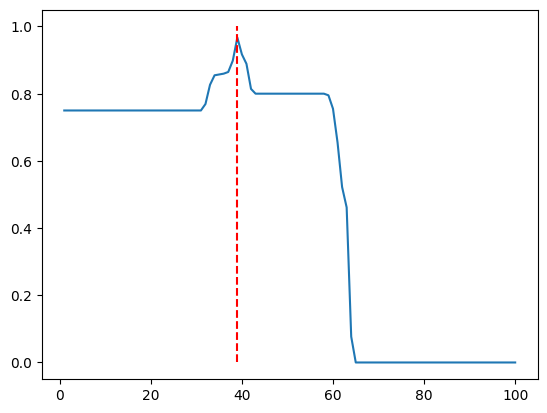

In [33]:
%%time
from sklearn.metrics import f1_score
'''
def find_robust_threshold(mean_probs_per_patient):

    
    best_f1 = -1
    best_thr = -1
    tot_per_tr_f1_scores = []
    threshold_predictions = []
    
    for threshold in list(range(1,101)):

        """ Concatenate mean probs and labels into two nsubset x timepoints lists """
        f1_scores = []
        patient_predictions = []
        resampled_ys = []
        probs = []
        for patient_probs_tuple in mean_probs_per_patient:
            
            for timep, timep_res_y in patient_probs_tuple:
                
                # get mean columns predicted probabilities 
                probs += list(timep)
                
                # get the resampled ys
                resampled_ys += list(timep_res_y)

        #print('Log: Concatenation: Done!')
            
        y_pred = []
        y_pred = (np.array(probs) >= threshold*0.01).astype(int) #checks column by column if the element is > than the threshold and converts it in 1 or 0
        #print(f'Threshold: {threshold*0.01}. Preds: {y_pred}')

        # compute f1 score on the concatenated timepoints results 
        total_f1_score = f1_score(resampled_ys, y_pred, pos_label = 1, zero_division=1)
        #print(f'f1_score: {total_f1_score}\n')
        
        tot_per_tr_f1_scores.append(total_f1_score) # Visualization purposes
        
        if total_f1_score > best_f1:
                best_f1 = total_f1_score
                best_thr = threshold*0.01
        #print('')
    
    """ Best Threshold selection section """
    #find threshold
    max_f1 = max(tot_per_tr_f1_scores)
    best_thresholds_idx = []
    
    best_thresholds_idx = [i for i, f1 in enumerate(tot_per_tr_f1_scores) if f1 == max_f1]

    # whether multiple threholds provides the maximum f1_score, the median is taken
    best_threshold = np.median(best_thresholds_idx)
    print(best_threshold)
    plt.plot(list(range(1, 101)), tot_per_tr_f1_scores)
    plt.vlines(x=best_threshold + 1, ymin = 0, ymax = 1, color='red', linestyle='--')
    print(f'Chosen threshold: {best_threshold + 1}. Associated F1_score: {tot_per_tr_f1_scores[int(best_threshold)]}' )
    
    return best_threshold + 1, tot_per_tr_f1_scores
'''
best_threshold = 0
best_threshold, tot_per_tr_f1_scores = find_robust_threshold(mean_probs_per_patient)

print(tot_per_tr_f1_scores)
#del per_donor_resampled_y

In [34]:
end = time.time() - start
print(f'{end/60} minutes')

2.1129058480262755 minutes


In [35]:
best_threshold

39.0

In [36]:

save_path = f'{fixed_path}CellCNN\\results\\old\\'
folder_name = f'model_{model_setting}'
model_save_path = f'{save_path}{folder_name}\\'
os.makedirs(model_save_path, exist_ok=True)

with open(f'{model_save_path}original_old_threshold.json', "w", encoding="utf-8") as f:
    json.dump(best_threshold, f, default=default_serializer, ensure_ascii=False, indent=2)

with open(f'{model_save_path}original_old_tuning_thr_f1_scores.json', "w", encoding="utf-8") as f:
    json.dump(tot_per_tr_f1_scores, f, default=default_serializer, ensure_ascii=False, indent=2)


# Test label prediction

In [37]:
import time
start = time.time()


In [38]:

def sub_resampling_list(k, nsub_per_sub = 50):
    remaining_k = k
    sub_division = []
    
    while remaining_k > 0:
        print(remaining_k)
        if remaining_k >= nsub_per_sub:
            sub_division.append(nsub_per_sub)
            remaining_k -= nsub_per_sub
            print(sub_division)
        else:
            sub_division.append(remaining_k)
            return sub_division
    return sub_division
            
sub_division = sub_resampling_list(k, nsub_per_sub = 50)
print(sub_division)

50
[50]
[50]


In [39]:
%%time

per_donor_original_test_datasets, per_donor_original_test_y = retrieve_labels(test_datasets_extracted, remove = False)

n = 100000
k = 100
seed = 42
'''
def test_res_pred(models_lists, per_donor_original_test_datasets, n, k, seed, best_threshold, trials):
    
    counter = 1
    per_donor_resampled_test_datasets =[]
    per_donor_resampled_test_y = []
    per_donor_perc = []
    
    test_total_labels = []
    test_total_pred_lists = []
    test_total_trial_pred_lists = []
    
    for patient in per_donor_original_test_datasets:
        per_dataset_resampled_datasets = []
        per_dataset_resampled_ys = []
        per_dataset_perc = []
        patient_timepoints_labels = []
        patient_pred_list = []
        patient_trial_pred_list = []
        
        for file in patient:
            sub_division = sub_resampling_list(k, nsub_per_sub = 50)
            print(sub_division)
            total_resampled_y = []
            total_positive_probs = [[] for _ in range(trials)]
            print(total_positive_probs)
            division_positive_probs_mean = []
            print(f'Prediction {counter}')
            counter += 1
            
            for _, division in enumerate(sub_division):
                print(division)
                resampled_datasets, resampled_y, blast_perc, seed = subset_sampling(dataset = file, ncells = n, nsubsets = division, seed = seed)
                
                # predict labels 
                new_datasets_predictions_list, new_datasets_results_list = trials_test_CellCNN_old(models_lists, resampled_datasets)
                positive_probs = []
                
                """ Extraction and mean probabilities section """
                for iterat, trial in enumerate(new_datasets_predictions_list):
                    positive_probs.append(pd.DataFrame(trial)[1].values) # appends the probability of positive classification
                    total_positive_probs[iterat] += list(pd.DataFrame(trial)[1].values)
        
                 #it converts the list of (list of) probabilities into an array of lists of prob
                
                # Computes the mean over the columns ( it takes the first element of all arrays and make the mean, then the second and so on)
                division_positive_probs_mean.append(np.mean(positive_probs , axis=0))
                
                total_resampled_y += resampled_y

            positive_probs_mean = np.concatenate(division_positive_probs_mean)
            #print(f'Len of Mean: {len(positive_probs_mean)}')
            #print(f'Len of probs: {len(total_positive_probs)}')
            """ Threshold prediction section """
            mean_timepoint_probs = np.mean(positive_probs_mean) # mean percentage of timepoints labelled as with blast cells
                
            if mean_timepoint_probs >= best_threshold*0.01:
                    patient_timepoints_labels.append(1)
            else:
                    patient_timepoints_labels.append(0)
            
            
            patient_pred_list.append(positive_probs_mean) # stores the mean subset probabilities
            patient_trial_pred_list.append(total_positive_probs) # stores all probabilities af all trials
            
            per_dataset_resampled_ys.append(total_resampled_y)
            
        test_total_labels.append(patient_timepoints_labels)
        test_total_pred_lists.append(patient_pred_list)
        
        test_total_trial_pred_lists.append(patient_trial_pred_list)
        per_donor_resampled_test_y.append(per_dataset_resampled_ys)
    
    return test_total_labels, test_total_pred_lists, test_total_trial_pred_lists, per_donor_resampled_test_y
'''

test_total_labels, test_total_pred_lists, test_total_trial_pred_lists, per_donor_resampled_test_y = test_res_pred(models_lists, per_donor_original_test_datasets, n, k, seed, best_threshold, trials) 
#[patient1,                                               ... , patient5]
#[[patient1_timepoint1_probs, patient1_timepoint2_probs], ... ,[patient5_timepoint1_probs, patient5_timepoint2_probs]]


100
[50]
50
[50, 50]
[50, 50]
[[], [], [], [], [], [], [], [], [], []]
Prediction 1
50
10
Prediction started...


C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validat

2/2 [==============================] - 0s 98ms/step
Done
Trial 1 Done!

10
Prediction started...


C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validat

2/2 [==============================] - 0s 65ms/step
Done
Trial 2 Done!

10
Prediction started...


C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validat

... (511 outputs left out)

C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validat

2/2 [==============================] - 0s 76ms/step
Done
Trial 9 Done!

10
Prediction started...


C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validat

2/2 [==============================] - 0s 52ms/step
Done
Trial 10 Done!

CPU times: total: 19min 53s
Wall time: 11min 19s


In [40]:
print(test_total_labels)
#[[1, 1], [1, 1], [0], [1, 1, 0], [1, 0], [1, 1, 0]]

[[1, 1], [1, 1], [0], [1, 1, 1], [1, 0], [1, 1, 0]]


In [41]:
print_var_memory()

Variable                  Type                          Memory
-----------------------------------------------------------------
per_donor_original_test_datasets list                         1.13 GB
test_datasets_extracted   list                         1.13 GB
original_test_datasets    list                         1.03 GB
train_datasets_extracted  list                       407.55 MB
per_donor_original_val_datasets list                       365.19 MB
val_datasets_extracted    list                       365.19 MB
donor                     list                       313.98 MB
pat                       list                       313.98 MB
new_test_datasets         list                       201.42 MB
new_train_datasets        list                       128.18 MB
new_val_datasets          list                        91.56 MB
-----------------------------------------------------------------
TOTAL                                                  5.42 GB


['per_donor_original_test_datasets',
 'test_datasets_extracted',
 'original_test_datasets',
 'train_datasets_extracted',
 'per_donor_original_val_datasets',
 'val_datasets_extracted',
 'donor',
 'pat',
 'new_test_datasets',
 'new_train_datasets',
 'new_val_datasets']

In [42]:
def flatten(nested):
    if nested is None:
        return []
    if not isinstance(nested, (list, tuple)):
        return [nested]
    nested = list(nested)
    result = []
    for item in nested:
        result.extend(flatten(item))
    return result
    
test_total_labels = test_total_labels
print(test_total_labels)

predicted_labels = flatten(test_total_labels)
true_labels = flatten(per_donor_original_test_y)
print(predicted_labels)
print(true_labels)

f1 = f1_score(predicted_labels, true_labels, pos_label = 1, zero_division=1)
print(f1)

[[1, 1], [1, 1], [0], [1, 1, 1], [1, 0], [1, 1, 0]]
[1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0]
[1, 1, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0]
0.9473684210526315


In [43]:

save_path = f'{fixed_path}CellCNN\\results\\old\\'
folder_name = f'model_{model_setting}'
model_save_path = f'{save_path}{folder_name}\\'
os.makedirs(model_save_path, exist_ok=True)

with open(f'{model_save_path}original_old_trials_pred_lists.json', "w", encoding="utf-8") as f:
    json.dump(test_total_trial_pred_lists, f, default=default_serializer, ensure_ascii=False, indent=2)

with open(f'{model_save_path}original_old_per_donor_resampled_test_y.json', "w", encoding="utf-8") as f:
    json.dump(per_donor_resampled_test_y, f, default=default_serializer, ensure_ascii=False, indent=2)

with open(f'{model_save_path}original_old_per_donor_resampled_test_y.json', "w", encoding="utf-8") as f:
    json.dump(per_donor_resampled_test_y, f, default=default_serializer, ensure_ascii=False, indent=2)


timepoints_blast_perc = []
for donor in per_donor_original_test_datasets:
    for i, dataset in enumerate(donor):
        blast_n = (dataset['IsBlast'] == 1).sum()/len(dataset)
        timepoints_blast_perc.append(round(blast_n*100,4))
        
with open(f'{model_save_path}original_old_timepoints_blast_perc.json', "w", encoding="utf-8") as f:
    json.dump(timepoints_blast_perc, f, default=default_serializer, ensure_ascii=False, indent=2)

Predicted  Labels: [[1, 1], [1, 1], [0], [1, 1, 1], [1, 0], [1, 1, 0]]
Timepoints Labels: [[1, 1], [1, 1], [0], [1, 1, 0], [1, 0], [1, 1, 0]]


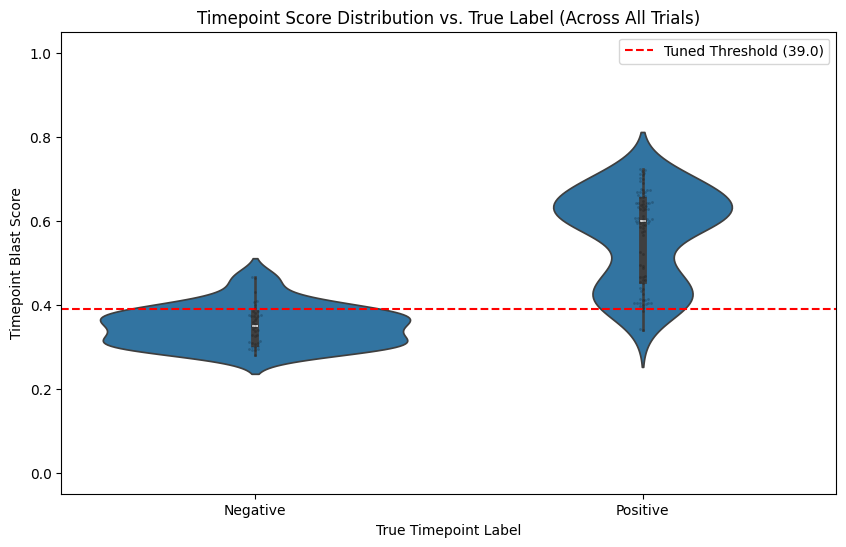

In [44]:
from sklearn.metrics import f1_score
'''
def final_trials_prediction(total_trial_pred_lists, per_donor_original_test_y, per_donor_resampled_test_y, best_threshold):
    from sklearn.metrics import f1_score
    """ Elaborate data to show distribution of trial results over the entire set of timepoints and patiets"""
    prob_data = []
    f1_data = []
    boxplot_data = []
    
    for patient, patient_ys, patient_resampled_y in zip(total_trial_pred_lists, per_donor_original_test_y, per_donor_resampled_test_y):

        for timepoint, true_timepoint_y, true_resampled_y in zip(patient, patient_ys, patient_resampled_y):
            label_str = "Positive" if true_timepoint_y == 1 else "Negative"
            
            timepoint_boxplot_data = []
            timepoint_f1_data = []
            #print(timepoint)
            for trial in timepoint: # from each timepoint multiple samples has been generated. each sample has been predicted 10 times using the same 'best' model but using a different seed each time
                             # each sub is a pediction of the 20 samples of a single timepoint

                #print(trial)
                trial_prob = np.mean(trial) # mean of the probabilities of the subsets
                
                trial_pred = (np.array(trial) >= best_threshold*0.01).astype(int)
                #print(trial_pred)
                #print(true_resampled_y)
                
                trial_f1 =  f1_score(true_resampled_y, trial_pred, pos_label = 1, zero_division=1)
                #print(rqver)
                
                prob_data.append({
                "True_Label": label_str,
                "Timepoint_Score": trial_prob
                })
                
                
                timepoint_boxplot_data.append(trial_prob)
                timepoint_f1_data.append(trial_f1)
                
            boxplot_data.append({
                "True_Label": true_timepoint_y,
                "Timepoint_trials_scores": timepoint_boxplot_data
                })
            
            f1_data.append({
                "True_Label": true_timepoint_y,
                "Timepoint_trials_scores": timepoint_f1_data
                })
                
    return prob_data, boxplot_data, f1_data
'''
    
print(f'Predicted  Labels: {test_total_labels}')

print(f'Timepoints Labels: {per_donor_original_test_y}')

plot_data, boxplot_data, f1_data = final_trials_prediction(test_total_trial_pred_lists, 
                                                           per_donor_original_test_y, per_donor_resampled_test_y, best_threshold)
#print(plot_data)

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Convert your data into a DataFrame
df = pd.DataFrame(plot_data)

# --- Create the plot ---
plt.figure(figsize=(10, 6))

# A Violin plot is like a boxplot but shows the full distribution
sns.violinplot(
    x="True_Label", 
    y="Timepoint_Score", 
    data=df,
    order=["Negative", "Positive"] # Ensure this order
)

# You can also add a swarmplot to see the individual points
sns.swarmplot(
    x="True_Label",
    y="Timepoint_Score",
    data=df,
    color="black",
    alpha=0.2, # Make points transparent
    size=2,
    order=["Negative", "Positive"]
)

# --- Add your threshold line! ---
# This is the line that separates your predictions
TUNED_THRESHOLD = best_threshold # The threshold you found in your tuning
plt.axhline(y=TUNED_THRESHOLD*0.01, color='red', linestyle='--', label=f'Tuned Threshold ({TUNED_THRESHOLD})')
plt.ylim(-0.05, 1.05) # (Set the y-axis limit, 1.05 gives a little space)
plt.title('Timepoint Score Distribution vs. True Label (Across All Trials)')
plt.ylabel('Timepoint Blast Score')
plt.xlabel('True Timepoint Label')
plt.legend()
plt.show()


C:\Users\Enrico Didoli\AppData\Local\Temp\ipykernel_9288\2472743216.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax1.boxplot(timepoints_trials_scores, labels=timepoints_labels)


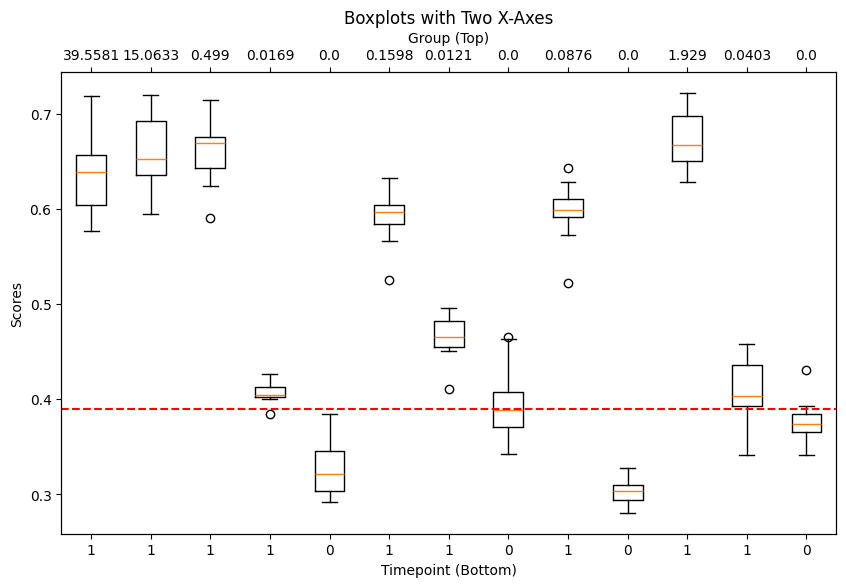

In [45]:
#print(boxplot_data)

timepoints_labels = [timepoint["True_Label"] for i, timepoint in enumerate(boxplot_data)]
timepoints_trials_scores = [timepoint["Timepoint_trials_scores"] for timepoint in boxplot_data]
#print(timepoints_labels)
#print(timepoints_trials_scores)

# --- Your Solution (One Line) ---
# Create a figure and axes
fig, ax1 = plt.subplots(figsize=(10, 6))

# 2. Plot the boxplot on the first axes (ax1)
ax1.boxplot(timepoints_trials_scores, labels=timepoints_labels)
ax1.set_xlabel("Timepoint (Bottom)")
ax1.set_ylabel("Scores")

# 3. Create the SECOND axes (ax2)
ax2 = ax1.twiny()

# 4. Configure the second axes
# Make ax2 have the same limits and ticks as ax1
ax2.set_xlim(ax1.get_xlim())
ax2.set_xticks(ax1.get_xticks()) # Positions [1, 2, 3, 4]

# Set the new labels for the top axis
ax2.set_xticklabels(timepoints_blast_perc)
ax2.set_xlabel("Group (Top)")
plt.axhline(y=TUNED_THRESHOLD*0.01, color='red', linestyle='--', label=f'Tuned Threshold ({TUNED_THRESHOLD})')

plt.title("Boxplots with Two X-Axes")
plt.show()

C:\Users\Enrico Didoli\AppData\Local\Temp\ipykernel_9288\53204109.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax1.boxplot(f1_timepoints_trials_scores, labels=timepoints_labels)


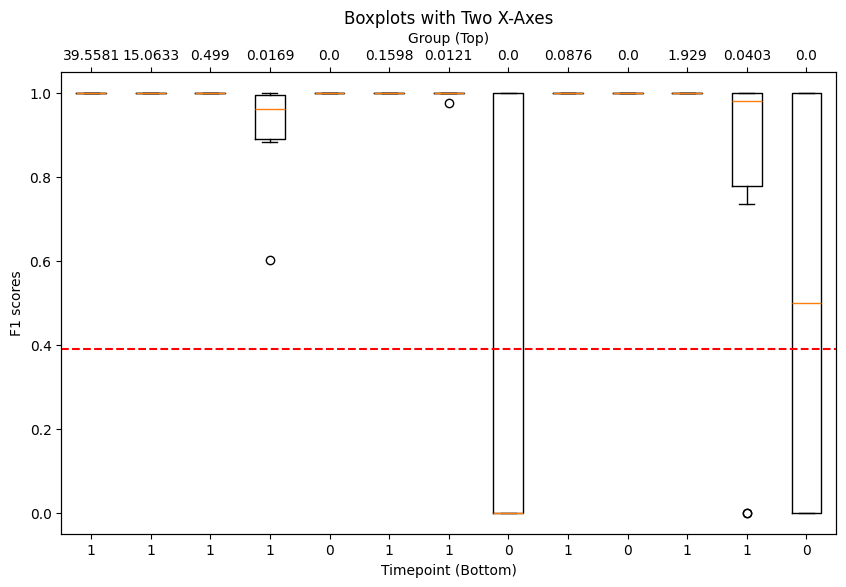

In [46]:
#print(boxplot_data)

timepoints_labels = [timepoint["True_Label"] for i, timepoint in enumerate(f1_data)]
f1_timepoints_trials_scores = [timepoint["Timepoint_trials_scores"] for timepoint in f1_data]
#print(timepoints_labels)
#print(timepoints_trials_scores)

# --- Your Solution (One Line) ---
# Create a figure and axes
fig, ax1 = plt.subplots(figsize=(10, 6))

# 2. Plot the boxplot on the first axes (ax1)
ax1.boxplot(f1_timepoints_trials_scores, labels=timepoints_labels)
ax1.set_xlabel("Timepoint (Bottom)")
ax1.set_ylabel("F1 scores")

# 3. Create the SECOND axes (ax2)
ax2 = ax1.twiny()

# 4. Configure the second axes
# Make ax2 have the same limits and ticks as ax1
ax2.set_xlim(ax1.get_xlim())
ax2.set_xticks(ax1.get_xticks()) # Positions [1, 2, 3, 4]

# Set the new labels for the top axis
ax2.set_xticklabels(timepoints_blast_perc)
ax2.set_xlabel("Group (Top)")
plt.axhline(y=TUNED_THRESHOLD*0.01, color='red', linestyle='--', label=f'Tuned Threshold ({TUNED_THRESHOLD})')

plt.title("Boxplots with Two X-Axes")
plt.show()

In [47]:
end = time.time() - start
print(f'{end/60} minutes')

11.416764179865519 minutes


In [50]:

def chosen_folds(iterations, train_perm, val_perm, seed = 42):
    print(seed)
    np.random.seed(seed)
    tot_perm = len(train_perm)
    
    idx = np.arange(tot_perm)
    np.random.shuffle(idx)

    chosen_folds = []
    for index in idx[:iterations]:
        chosen_folds.append([train_perm[index], val_perm[index]])
    
    return chosen_folds

iterations = 1
chosen_folds = chosen_folds(iterations, train_perm, val_perm, seed)
print(chosen_folds)

42
[[['15', '7', '12', '9'], ['6', '3', '13']]]


In [51]:
%%time
# Samples donors for Train, Validation and Test sets    
seed = 105619
multiple_donations, ALL_DATASETS = load_data(data_path = data_folder, ext = extension)
train_donors_idx, val_donors_idx, test_donors_idx = dataset_elaboration(multiple_donations, ALL_DATASETS, healthy_donors, blast_donors,
                        mixed_donors, seed = seed)



Elaborating file 0: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_220204-2900.csv
Elaborating file 1: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_220208-3665.csv
Elaborating file 2: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_220216-3546.csv
Elaborating file 3: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_B-ALL_GHE11_D15_1.csv
Elaborating file 4: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_B-ALL_GHE11_D29_1.csv
Elaborating file 5: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_B-ALL_GHE11_D71_1.csv
Elaborating file 6: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_B-ALL_GHE12_D15_2.csv
Elaborating file 7: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_B-ALL_GHE12_D29_1.csv
Elaborating file 8: C:\Users\Enrico Didoli\0.Master_Thesis

In [52]:
def min_thr_tuning_subsets(datasets_extracted, donors_idx = None):
    max_len = 0
    for i, pat in enumerate(datasets_extracted):
        for j, ds in enumerate(pat):
            if len(ds) > max_len:
                max_len = len(ds)
                
            if donors_idx is not None:
                print(f'Patient {donors_idx[i]}: cells: {len(ds)}')
    
    min_perc = 1/max_len
    min_sub_to_sample = np.log(min_perc/max_len)/np.log(0.51923)
    
    return int(min_sub_to_sample) + 1

min_sub_to_sample_val = min_thr_tuning_subsets(val_datasets_extracted, donors_idx = None)
min_sub_to_sample_test = min_thr_tuning_subsets(test_datasets_extracted, donors_idx = None)
#del pat
print(f'Subset to sample in Threshold Tuning: {min_sub_to_sample_val}')
print(f'Subset to sample in Label Prediction: {min_sub_to_sample_test}')

Subset to sample in Threshold Tuning: 46
Subset to sample in Label Prediction: 48
